In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-box-plot

**Figure 3: Response lengths of the base model and our RL-trained model on three datasets.** Boxes span the quartiles with the median as a line; whiskers reach 1.5× the interquartile range, and points mark responses beyond the whiskers (60 responses per box). RL training lengthens responses on every dataset, most on AIME, where the median grows by 798 tokens (873 → 1,670), against 124 on GSM8K and 377 on MATH.

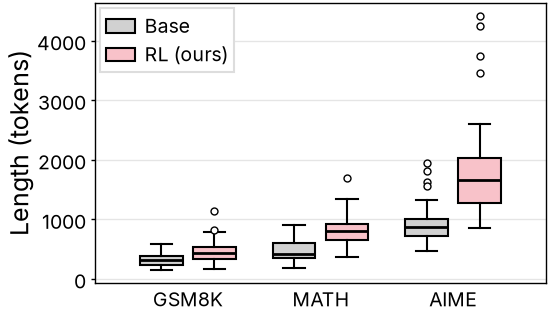

In [2]:
from matplotlib.patches import Patch

with open("../data/grouped-box-plot.json") as f:
    data = json.load(f)

datasets = data["datasets"]
models = [("Base", colors["neutral"]), ("RL (ours)", colors["ours"])]
width = 0.8 / len(models)

fig, ax = plt.subplots(figsize=(2.75, 2))
for i, (model, color) in enumerate(models):
    for x, dataset in enumerate(datasets):
        box = ax.boxplot(data["lengths"][model][dataset], positions=[x + (i - (len(models) - 1) / 2) * width],
                         widths=0.8 * width)
        box["boxes"][0].set_facecolor(lighten(color))
ax.set_xticks(range(len(datasets)), labels=datasets)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Length (tokens)")
ax.legend(handles=[Patch(facecolor=lighten(color), edgecolor="black", linewidth=0.75, label=model)
                   for model, color in models], loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/grouped-box-plot.pdf")
fig.savefig("../outputs/grouped-box-plot.png")
plt.show()